**Segmentasi Citra Berbasis Similaritas: Clustering dan Watershed**

---

### 1. Konsep Segmentasi Berbasis Clustering

Segmentasi berbasis clustering memanfaatkan algoritma pembelajaran tak terawasi (unsupervised learning) untuk mengelompokkan piksel berdasarkan fitur seperti intensitas, warna, atau koordinat spasial.

Algoritma yang umum digunakan:

* **K-Means Clustering**: Mengelompokkan piksel ke dalam *k* klaster berdasarkan jarak ke pusat klaster.
* **Mean Shift**, **DBSCAN**, dan lain-lain.

### 2. Implementasi K-Means Clustering


libpng warning: iCCP: extra compressed data


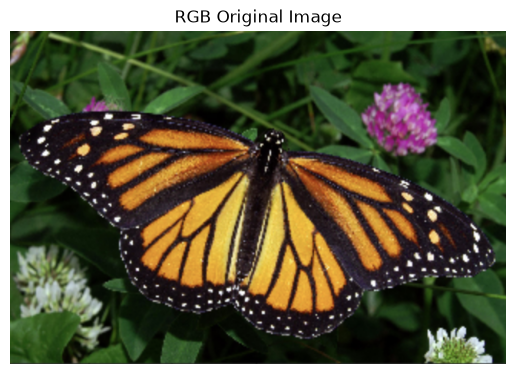

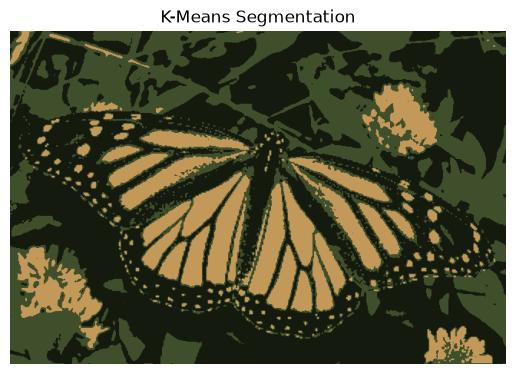

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('image_clustering_segmentation.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.title('RGB Original Image')
plt.axis('off')
plt.show()

Z = img_rgb.reshape((-1,3))
Z = np.float32(Z)

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
K = 3
ret,label,center=cv2.kmeans(Z,K,None,criteria,10,cv2.KMEANS_RANDOM_CENTERS)

center = np.uint8(center)
res = center[label.flatten()]
segmented_img = res.reshape((img.shape))

plt.imshow(segmented_img)
plt.title('K-Means Segmentation')
plt.axis('off')
plt.show()


### 3. Konsep Segmentasi Watershed

Watershed adalah algoritma berbasis morfologi yang memodelkan citra sebagai topografi. Area terang (intensitas tinggi) dianggap sebagai puncak dan area gelap (intensitas rendah) sebagai lembah. Tujuannya adalah membanjiri lembah dari marker (penanda), lalu membuat batas di titik pertemuan antara banjir.
Watershed efektif jika dikombinasikan dengan marker dan preprocessing.

### 4. Implementasi Watershed di Python


libpng warning: iCCP: extra compressed data


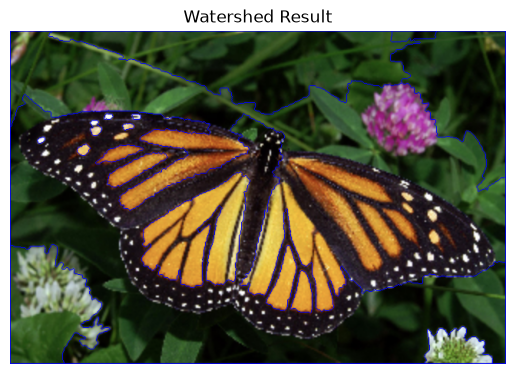

In [11]:
img = cv2.imread('image_clustering_segmentation.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Noise removal
kernel = np.ones((3,3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# Sure background
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# Sure foreground
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
ret, sure_fg = cv2.threshold(dist_transform, 0.7*dist_transform.max(), 255, 0)

# Unknown region
sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)

# Marker labelling
ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

markers = cv2.watershed(img, markers)
img[markers == -1] = [255, 0, 0]

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Watershed Result')
plt.axis('off')
plt.show()


---

### 5. Visualisasi Eksperimen Tambahan

#### Menguji jumlah klaster *K* yang berbeda pada K-Means:


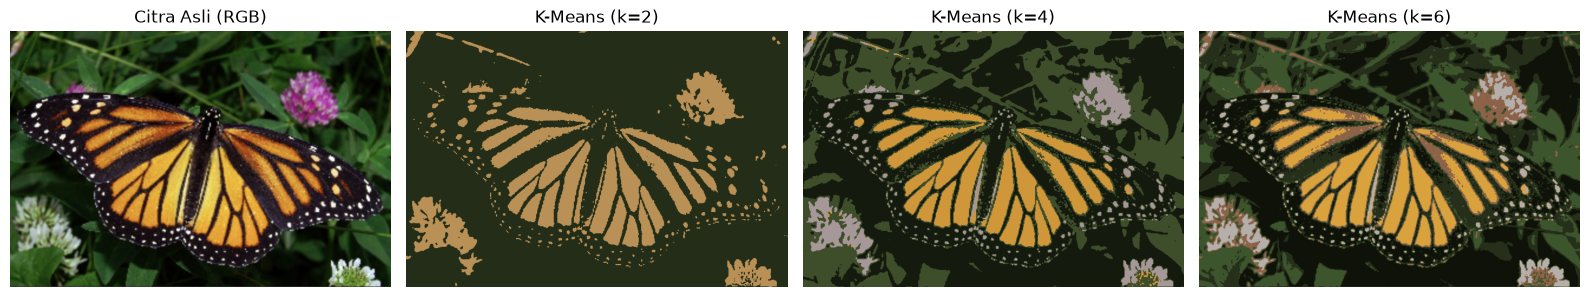

In [12]:
# Menguji jumlah klaster K yang berbeda pada K-Means
plt.figure(figsize=(16, 4))

# Tampilkan citra asli
plt.subplot(1, 4, 1)
plt.imshow(img_rgb)
plt.title('Citra Asli (RGB)')
plt.axis('off')

# Gunakan data piksel Z yang telah di-reshape
Z = img_rgb.reshape((-1, 3)).astype(np.float32)

for idx, k in enumerate([2, 4, 6], start=2):
    _, labels, centers = cv2.kmeans(Z, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    centers = np.uint8(centers)
    segmented_img = centers[labels.flatten()].reshape(img.shape)
    
    plt.subplot(1, 4, idx)
    plt.imshow(segmented_img)
    plt.title(f'K-Means (k={k})')
    plt.axis('off')

plt.tight_layout()
plt.show()


#### Menambahkan Preprocessing dengan CLAHE untuk Watershed:


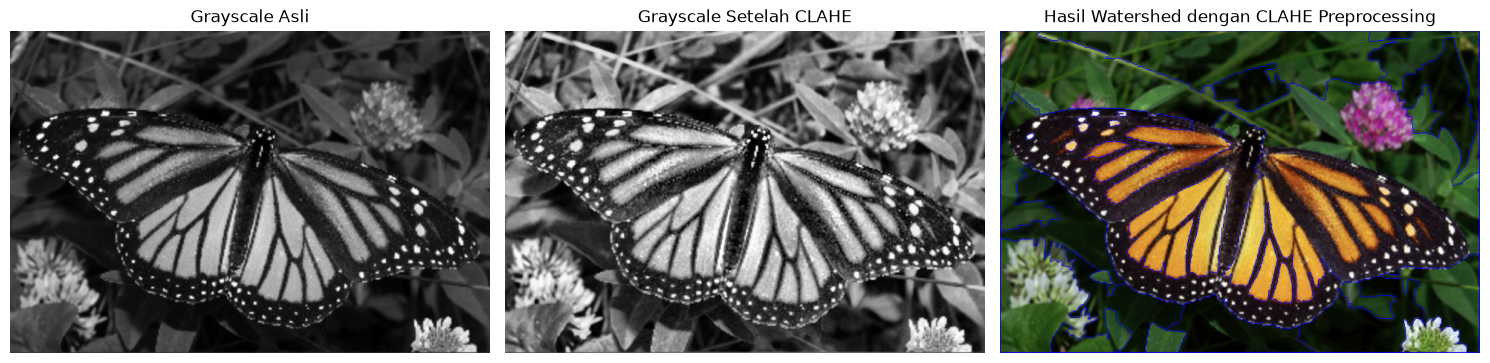

In [13]:
# 1. Terapkan CLAHE untuk meningkatkan kontras lokal pada citra grayscale
clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
gray_clahe = clahe.apply(gray)

# 2. Thresholding Otsu pada hasil CLAHE
ret, thresh_clahe = cv2.threshold(gray_clahe, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 3. Operasi morfologi untuk menghilangkan noise
kernel = np.ones((3, 3), np.uint8)
opening_clahe = cv2.morphologyEx(thresh_clahe, cv2.MORPH_OPEN, kernel, iterations=2)

# Area latar belakang pasti (sure background)
sure_bg_clahe = cv2.dilate(opening_clahe, kernel, iterations=3)

# Area latar depan pasti (sure foreground) via Distance Transform
dist_transform_clahe = cv2.distanceTransform(opening_clahe, cv2.DIST_L2, 5)
ret, sure_fg_clahe = cv2.threshold(dist_transform_clahe, 0.7 * dist_transform_clahe.max(), 255, 0)
sure_fg_clahe = np.uint8(sure_fg_clahe)

# Area belum teridentifikasi (unknown region)
unknown_clahe = cv2.subtract(sure_bg_clahe, sure_fg_clahe)

# 4. Pelabelan marker terhubung dan eksekusi Watershed
ret, markers_clahe = cv2.connectedComponents(sure_fg_clahe)
markers_clahe = markers_clahe + 1
markers_clahe[unknown_clahe == 255] = 0

img_watershed_clahe = img.copy()
markers_clahe = cv2.watershed(img_watershed_clahe, markers_clahe)
img_watershed_clahe[markers_clahe == -1] = [255, 0, 0]  # Garis batas merah

# 5. Visualisasi perbandingan: Sebelum vs Sesudah CLAHE
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(gray, cmap='gray')
plt.title('Grayscale Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gray_clahe, cmap='gray')
plt.title('Grayscale Setelah CLAHE')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_watershed_clahe, cv2.COLOR_BGR2RGB))
plt.title('Hasil Watershed dengan CLAHE Preprocessing')
plt.axis('off')

plt.tight_layout()
plt.show()


#### Menggabungkan Watershed dengan Deteksi Tepi dan Thresholding untuk Marker Lebih Akurat:


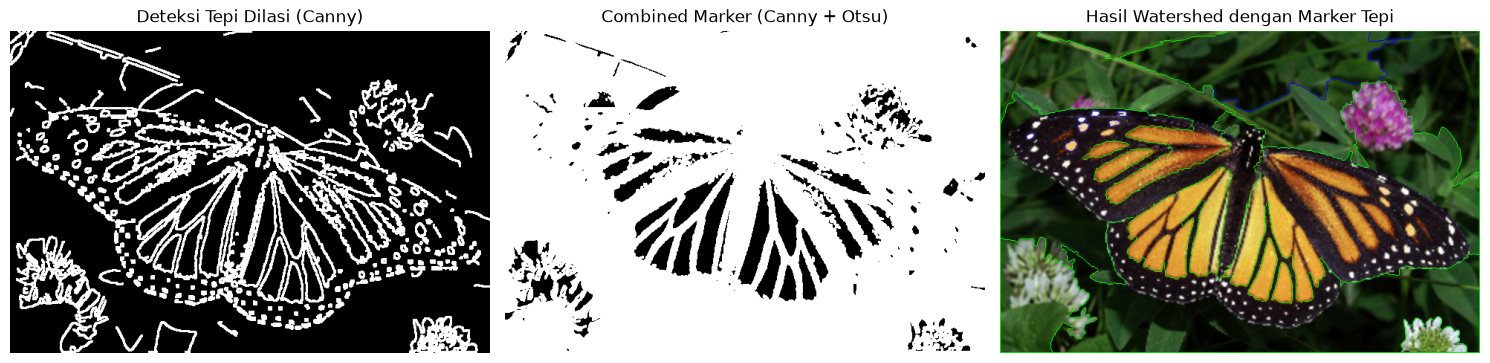

In [14]:
# 1. Deteksi tepi dengan Canny dan dilasi untuk menyambung fragmen garis tepi
edges = cv2.Canny(gray, 100, 200)
kernel = np.ones((3, 3), np.uint8)
edges_dilated = cv2.dilate(edges, kernel, iterations=1)

# 2. Thresholding Otsu
ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 3. Gabungkan tepi dengan thresholding untuk membentuk batas marker yang lebih kokoh
combined_marker = cv2.bitwise_or(edges_dilated, thresh)

# 4. Pembersihan morfologi dan penentuan sure foreground melalui Distance Transform
opening_comb = cv2.morphologyEx(combined_marker, cv2.MORPH_OPEN, kernel, iterations=2)
sure_bg_comb = cv2.dilate(opening_comb, kernel, iterations=3)

dist_transform_comb = cv2.distanceTransform(opening_comb, cv2.DIST_L2, 5)
ret, sure_fg_comb = cv2.threshold(dist_transform_comb, 0.5 * dist_transform_comb.max(), 255, 0)
sure_fg_comb = np.uint8(sure_fg_comb)
unknown_comb = cv2.subtract(sure_bg_comb, sure_fg_comb)

# 5. Pelabelan marker dan eksekusi Watershed
ret, markers_comb = cv2.connectedComponents(sure_fg_comb)
markers_comb = markers_comb + 1
markers_comb[unknown_comb == 255] = 0

img_watershed_edge = img.copy()
markers_comb = cv2.watershed(img_watershed_edge, markers_comb)
img_watershed_edge[markers_comb == -1] = [0, 255, 0]  # Garis batas hijau

# 6. Visualisasi tahapan integrasi
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(edges_dilated, cmap='gray')
plt.title('Deteksi Tepi Dilasi (Canny)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(combined_marker, cmap='gray')
plt.title('Combined Marker (Canny + Otsu)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_watershed_edge, cv2.COLOR_BGR2RGB))
plt.title('Hasil Watershed dengan Marker Tepi')
plt.axis('off')

plt.tight_layout()
plt.show()


#### Mengkombinasikan Clustering dan Watershed untuk Segmentasi Lebih Akurat:
Gabungan clustering (misalnya K-Means) dan watershed dapat meningkatkan akurasi segmentasi.
* Gunakan hasil clustering sebagai dasar penentuan marker.
* Terapkan watershed berdasarkan hasil threshold dari cluster tertentu atau perbedaan antar cluster.


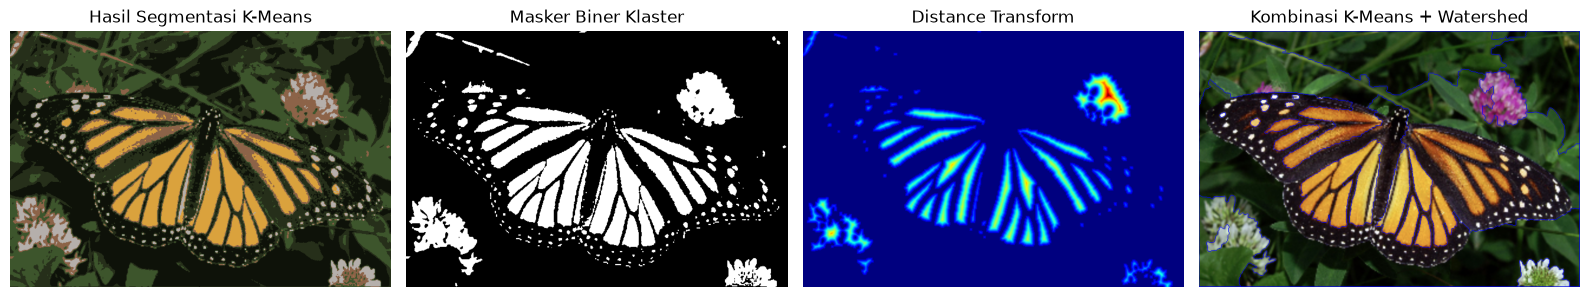

In [15]:
# 1. Gunakan hasil clustering K-Means (segmented_img) sebagai dasar penentuan marker
gray_clustered = cv2.cvtColor(segmented_img, cv2.COLOR_RGB2GRAY)
ret, thresh_clustered = cv2.threshold(gray_clustered, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Preprocessing morfologi untuk marker
kernel = np.ones((3, 3), np.uint8)
opening_cluster = cv2.morphologyEx(thresh_clustered, cv2.MORPH_OPEN, kernel, iterations=2)
sure_bg_cluster = cv2.dilate(opening_cluster, kernel, iterations=3)

# 3. Distance Transform untuk mendapatkan pusat klaster
dist_transform_cluster = cv2.distanceTransform(opening_cluster, cv2.DIST_L2, 5)
ret, sure_fg_cluster = cv2.threshold(dist_transform_cluster, 0.7 * dist_transform_cluster.max(), 255, 0)
sure_fg_cluster = np.uint8(sure_fg_cluster)
unknown_cluster = cv2.subtract(sure_bg_cluster, sure_fg_cluster)

# 4. Pelabelan marker terhubung
ret, markers_cluster = cv2.connectedComponents(sure_fg_cluster)
markers_cluster = markers_cluster + 1
markers_cluster[unknown_cluster == 255] = 0

# 5. Terapkan Watershed pada salinan citra asli
img_watershed_cluster = img.copy()
markers_cluster = cv2.watershed(img_watershed_cluster, markers_cluster)
img_watershed_cluster[markers_cluster == -1] = [255, 0, 0]  # Garis batas merah

# 6. Visualisasi tahapan kombinasi
plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1)
plt.imshow(segmented_img)
plt.title('Hasil Segmentasi K-Means')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(thresh_clustered, cmap='gray')
plt.title('Masker Biner Klaster')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(dist_transform_cluster, cmap='jet')
plt.title('Distance Transform')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(cv2.cvtColor(img_watershed_cluster, cv2.COLOR_BGR2RGB))
plt.title('Kombinasi K-Means + Watershed')
plt.axis('off')

plt.tight_layout()
plt.show()


---

### 6. Kesimpulan

* Segmentasi berbasis clustering efektif untuk pemisahan objek berdasarkan kesamaan warna/intensitas (tekstur homogen), sementara watershed sangat baik untuk segmentasi objek bersentuhan (objek dengan batas yang jelas).
* Eksperimen parameter penting untuk mendapatkan hasil segmentasi terbaik.
* Preprocessing seperti CLAHE, serta deteksi tepi dan thresholding sangat membantu dalam memperjelas batas objek.
* Kombinasikan Clustering dan Watershed dapat menghasilkan segmentasi yang lebih akurat.


---

### 7. Eksperimen Tambahan

1. **Mean-Shift Clustering Segmentation**: Algoritma clustering non-parametrik berbasis estimasi kepadatan probabilitas (*density estimation*) dan pencarian modus (*mode-seeking*). Berbeda dengan K-Means yang mengasumsikan klaster berbentuk bola sferis dengan jumlah $k$ tetap, Mean-Shift mampu menemukan klaster dengan bentuk sembarang secara otomatis.
2. **Morphological Watershed pada Citra Gradient**: Watershed yang diaplikasikan langsung pada topografi citra gradien (*gradient magnitude*), di mana batas objek tampak sebagai pegunungan tinggi (*catchment basin boundaries*).
3. **Pengaruh Ruang Warna Terhadap Clustering K-Means** : Mengeksplorasi representasi ruang warna (seperti $L^*u^*v^*$ dan $L^*a^*b^*$) untuk memisahkan intensitas pencahayaan (*luminance*) dari informasi warna murni (*chrominance*), sehingga segmentasi tahan terhadap bayangan.


#### 7.1 Mean-Shift Clustering Segmentation

Mean-Shift mencari titik pusat massa (*center of mass*) dari suatu jendela spasial-warna dan menggeser jendela tersebut secara iteratif sampai konvergen ke modus lokal (*peak density*).
- Parameter `sp` (*spatial window radius*): Ukuran jendela jarak spasial piksel (koordinat x, y).
- Parameter `sr` (*color window radius*): Ukuran jendela rentang perbedaan intensitas/warna.


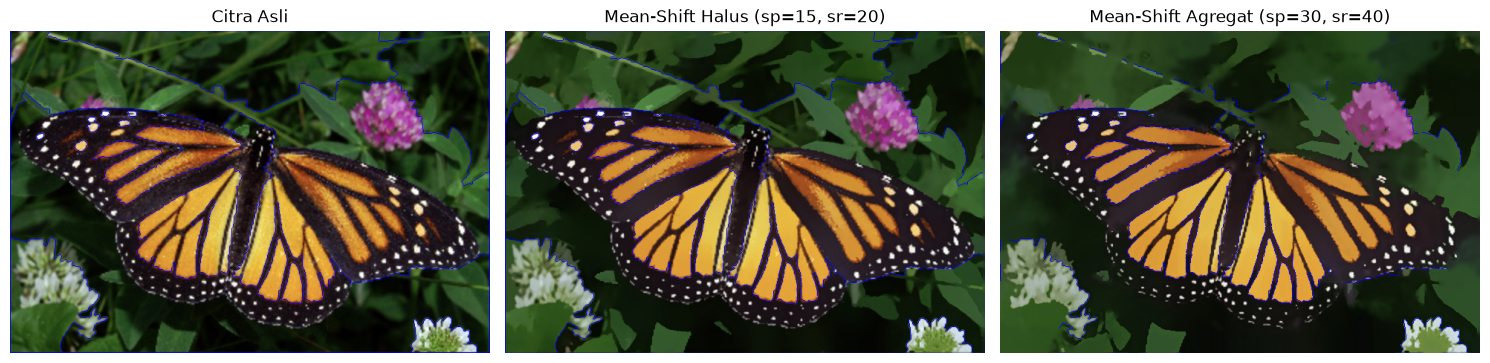

In [19]:
# 1. Mean-Shift dengan parameter fine (detail tinggi)
ms_fine = cv2.pyrMeanShiftFiltering(img, sp=15, sr=20, maxLevel=2)

# 2. Mean-Shift dengan parameter coarse (agregasi wilayah lebih besar)
ms_coarse = cv2.pyrMeanShiftFiltering(img, sp=30, sr=40, maxLevel=2)

# 3. Visualisasi perbandingan hasil Mean-Shift
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(ms_fine, cv2.COLOR_BGR2RGB))
plt.title('Mean-Shift Halus (sp=15, sr=20)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(ms_coarse, cv2.COLOR_BGR2RGB))
plt.title('Mean-Shift Agregat (sp=30, sr=40)')
plt.axis('off')

plt.tight_layout()
plt.show()


#### 7.2 Morphological Watershed pada Citra Gradient

Pada metode ini, gradien morfologi (selisih dilasi dan erosi) diperlakukan sebagai peta topografi elevasi. Proses banjir (*flooding*) dimulai dari cekungan regional (*catchment basins*) dan bendungan (*watershed dams*) dibangun tepat di puncak garis gradien.


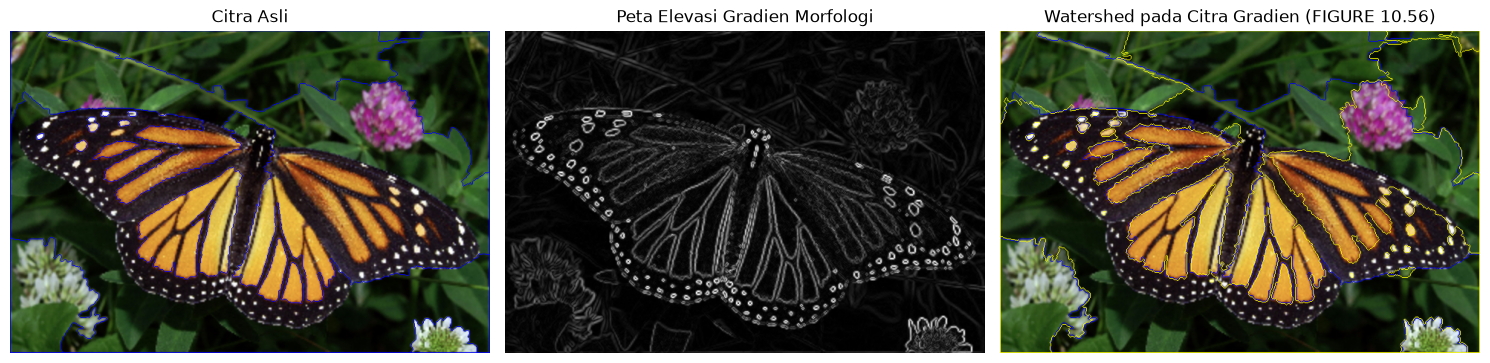

In [17]:
# 1. Hitung gradien morfologi (Dilation - Erosion) sebagai peta topografi elevasi
kernel_grad = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
gradient = cv2.morphologyEx(gray, cv2.MORPH_GRADIENT, kernel_grad)

# 2. Preprocessing thresholding untuk marker catchment basin
ret, thresh_grad = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
opening_grad = cv2.morphologyEx(thresh_grad, cv2.MORPH_OPEN, kernel_grad, iterations=2)
sure_bg_grad = cv2.dilate(opening_grad, kernel_grad, iterations=3)

dist_grad = cv2.distanceTransform(opening_grad, cv2.DIST_L2, 5)
ret, sure_fg_grad = cv2.threshold(dist_grad, 0.7 * dist_grad.max(), 255, 0)
sure_fg_grad = np.uint8(sure_fg_grad)
unknown_grad = cv2.subtract(sure_bg_grad, sure_fg_grad)

# 3. Pelabelan marker
ret, markers_grad = cv2.connectedComponents(sure_fg_grad)
markers_grad = markers_grad + 1
markers_grad[unknown_grad == 255] = 0

# 4. Terapkan watershed pada citra gradien 3-kanal
gradient_bgr = cv2.cvtColor(gradient, cv2.COLOR_GRAY2BGR)
markers_grad = cv2.watershed(gradient_bgr, markers_grad)

# 5. Tumpangkan garis batas watershed ke citra asli (seperti FIGURE 10.56 di slide 36)
img_watershed_topo = img.copy()
img_watershed_topo[markers_grad == -1] = [0, 255, 255]  # Garis kuning penanda batas

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gradient, cmap='gray')
plt.title('Peta Elevasi Gradien Morfologi')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_watershed_topo, cv2.COLOR_BGR2RGB))
plt.title('Watershed pada Citra Gradien (FIGURE 10.56)')
plt.axis('off')

plt.tight_layout()
plt.show()


#### 7.3 K-Means Clustering pada Berbagai Ruang Warna (RGB vs HSV vs CIE-Lab)



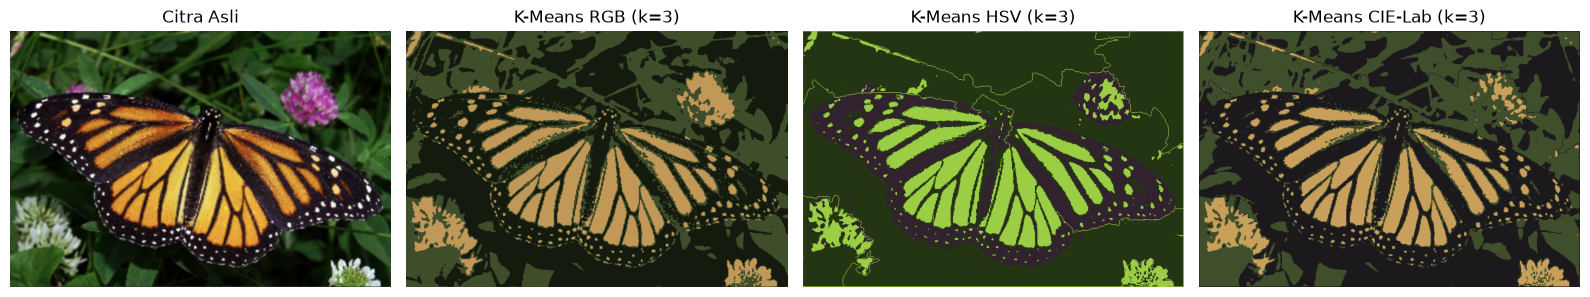

In [18]:
K_val = 3
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)

# 1. K-Means pada ruang warna RGB
Z_rgb = img_rgb.reshape((-1, 3)).astype(np.float32)
_, labels_rgb, centers_rgb = cv2.kmeans(Z_rgb, K_val, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
res_rgb = np.uint8(centers_rgb)[labels_rgb.flatten()].reshape(img.shape)

# 2. K-Means pada ruang warna HSV (memisahkan Hue & Saturation dari Value)
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
Z_hsv = img_hsv.reshape((-1, 3)).astype(np.float32)
_, labels_hsv, centers_hsv = cv2.kmeans(Z_hsv, K_val, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
res_hsv_clustered = np.uint8(centers_hsv)[labels_hsv.flatten()].reshape(img.shape)
res_hsv_rgb = cv2.cvtColor(res_hsv_clustered, cv2.COLOR_HSV2RGB)

# 3. K-Means pada ruang warna CIE-Lab (Luminance, a=green-red, b=blue-yellow)
img_lab = cv2.cvtColor(img, cv2.COLOR_BGR2Lab)
Z_lab = img_lab.reshape((-1, 3)).astype(np.float32)
_, labels_lab, centers_lab = cv2.kmeans(Z_lab, K_val, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
res_lab_clustered = np.uint8(centers_lab)[labels_lab.flatten()].reshape(img.shape)
res_lab_rgb = cv2.cvtColor(res_lab_clustered, cv2.COLOR_Lab2RGB)

# 4. Visualisasi perbandingan segmentasi antar ruang warna
plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1)
plt.imshow(img_rgb)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(res_rgb)
plt.title(f'K-Means RGB (k={K_val})')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(res_hsv_rgb)
plt.title(f'K-Means HSV (k={K_val})')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(res_lab_rgb)
plt.title(f'K-Means CIE-Lab (k={K_val})')
plt.axis('off')

plt.tight_layout()
plt.show()


#### Ringkasan Analisis Eksperimen Tambahan:

1. **Mean-Shift Segmentation**: Menghasilkan segmentasi berbasis perataan wilayah (*spatial-range smoothing*) yang sangat baik tanpa perlu mendefinisikan jumlah $K$ sebelumnya, serta mempertahankan tepi objek yang tajam.
2. **Watershed pada Citra Gradien**: Memberikan delineasi batas objek yang presisi dengan memanfaatkan lereng gradien sebagai dinding bendungan pemisah, mengurangi ambiguitas pada batas objek yang redup.
3. **Klasterisasi pada Ruang Warna Perseptual**: Ruang warna HSV dan CIE-Lab mengungguli RGB ketika citra memiliki variasi pencahayaan dan bayangan, karena komponen warna diproses secara independen dari intensitas cahaya.
